# **EDAV (22ADC32N) – Course-End Project**
## **Title: Retail Store Footfall Analysis and Visualization**

**Objective:**
To analyze retail store footfall data using NumPy, Pandas, Matplotlib, and Seaborn, identify patterns in footfall based on menu score, timing, holidays, and days, and visualize the results to obtain meaningful insights.


In [7]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/footfall_dataset_trial3.csv')

df.head()

,Date,Day,IsHoliday,Item1,Item2,ADD-ON,Timing,MenuScore,NoOfStudents
0,2025-06-01,Sunday,1,Arbi,Dum Aloo,Omelette,Breakfast,0,900
1,2025-06-02,Monday,0,Malai Kofta,Chole,Curd,Lunch,1,1069
2,2025-06-03,Tuesday,0,Tinda,Bhindi,Shahi Tukda,Dinner,-1,843
3,2025-06-04,Wednesday,0,Dum Aloo,New Dish,Egg Bhurji,Breakfast,1,1022
4,2025-06-05,Thursday,1,Khata Meetha,Green Moong Dal,Omelette,Breakfast,-1,892


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Date          1000 non-null   object
 1   Day           1000 non-null   object
 2   IsHoliday     1000 non-null   int64 
 3   Item1         1000 non-null   object
 4   Item2         1000 non-null   object
 5   ADD-ON        1000 non-null   object
 6   Timing        1000 non-null   object
 7   MenuScore     1000 non-null   int64 
 8   NoOfStudents  1000 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 70.4+ KB


In [9]:
df.isnull().sum()

,0
Date,0
Day,0
IsHoliday,0
Item1,0
Item2,0
ADD-ON,0
Timing,0
MenuScore,0
NoOfStudents,0


In [10]:
df.describe()

,IsHoliday,MenuScore,NoOfStudents
count,1000.000000,1000.000000,1000.000000
mean,0.356000,0.263000,946.112000
std,0.479055,0.764471,100.986582
min,0.000000,-1.000000,706.000000
25%,0.000000,0.000000,878.750000
50%,0.000000,0.000000,937.500000
75%,1.000000,1.000000,1018.000000
max,1.000000,1.000000,1198.000000


In [11]:
print( df.shape)

(1000, 9)


In [12]:
print(df.columns.tolist())

['Date', 'Day', 'IsHoliday', 'Item1', 'Item2', 'ADD-ON', 'Timing', 'MenuScore', 'NoOfStudents']


In [13]:
print(df.dtypes)

Date            object
Day             object
IsHoliday        int64
Item1           object
Item2           object
ADD-ON          object
Timing          object
MenuScore        int64
NoOfStudents     int64
dtype: object


In [14]:
df.describe()

,IsHoliday,MenuScore,NoOfStudents
count,1000.000000,1000.000000,1000.000000
mean,0.356000,0.263000,946.112000
std,0.479055,0.764471,100.986582
min,0.000000,-1.000000,706.000000
25%,0.000000,0.000000,878.750000
50%,0.000000,0.000000,937.500000
75%,1.000000,1.000000,1018.000000
max,1.000000,1.000000,1198.000000


In [15]:
# No.of Duplicate rows
print( df.duplicated().sum())

0


In [16]:
print("IsHoliday values:")
print(df['IsHoliday'].unique())

print("\nMenuScore values:")
print(df['MenuScore'].unique())

print("\nTiming values:")
print(df['Timing'].unique())

print("\nDay values:")
print(df['Day'].unique())

IsHoliday values:
[1 0]

MenuScore values:
[ 0  1 -1]

Timing values:
['Breakfast' 'Lunch' 'Dinner']

Day values:
['Sunday' 'Monday' 'Tuesday' 'Wednesday' 'Thursday' 'Friday' 'Saturday']


In [17]:
print("Minimum footfall:", df['NoOfStudents'].min())
print("Maximum footfall:", df['NoOfStudents'].max())

print("Negative footfall values:",
      (df['NoOfStudents'] < 0).sum())

Minimum footfall: 706
Maximum footfall: 1198
Negative footfall values: 0


## **NumPy Statistical Analysis**


In [18]:
score_minus_one = df.loc[df['MenuScore'] == -1, 'NoOfStudents'].to_numpy()
score_zero = df.loc[df['MenuScore'] == 0, 'NoOfStudents'].to_numpy()
score_one = df.loc[df['MenuScore'] == 1, 'NoOfStudents'].to_numpy()

In [19]:
df['MenuScore'] == 1

,MenuScore
0,False
1,True
2,False
3,True
4,False
...,...
995,False
996,True
997,False
998,True


In [20]:
import numpy as np
print("MenuScore -1")
print("Average:", np.mean(score_minus_one))
print("Minimum:", np.min(score_minus_one))
print("Maximum:", np.max(score_minus_one))

print("\nMenuScore 0")
print("Average:", np.mean(score_zero))
print("Minimum:", np.min(score_zero))
print("Maximum:", np.max(score_zero))

print("\nMenuScore 1")
print("Average:", np.mean(score_one))
print("Minimum:", np.min(score_one))
print("Maximum:", np.max(score_one))

MenuScore -1
Average: 849.8461538461538
Minimum: 706
Maximum: 996

MenuScore 0
Average: 916.400576368876
Minimum: 800
Maximum: 1050

MenuScore 1
Average: 1009.6091703056769
Minimum: 869
Maximum: 1198


# **Pandas GroupBy Analysis**


In [21]:
timing_analysis = df.groupby('Timing')['NoOfStudents'].mean()

print(timing_analysis)

Timing
Breakfast    950.320988
Dinner       939.529762
Lunch        948.605882
Name: NoOfStudents, dtype: float64


In [22]:
timing_analysis = df.groupby('Timing')['NoOfStudents'].agg(
    Count='count',
    Average='mean',
    Minimum='min',
    Maximum='max'
)

timing_analysis

,Count,Average,Minimum,Maximum
Timing,,,,
Breakfast,324,950.320988,721,1197
Dinner,336,939.529762,706,1195
Lunch,340,948.605882,719,1198


In [23]:
timing_analysis = df.groupby('Timing')['NoOfStudents'].agg(
    Count='count',
    Average='mean',
    Minimum='min',
    Maximum='max'
)

timing_analysis

,Count,Average,Minimum,Maximum
Timing,,,,
Breakfast,324,950.320988,721,1197
Dinner,336,939.529762,706,1195
Lunch,340,948.605882,719,1198


In [24]:
holiday_analysis = df.groupby('IsHoliday')['NoOfStudents'].agg(
    Count='count',
    Average='mean',
    Minimum='min',
    Maximum='max'
)

holiday_analysis

,Count,Average,Minimum,Maximum
IsHoliday,,,,
0,644,955.849379,715,1197
1,356,928.497191,706,1198


In [25]:
holiday_analysis.index = holiday_analysis.index.map({
    0: 'Non-Holiday',
    1: 'Holiday'
})

holiday_analysis

,Count,Average,Minimum,Maximum
IsHoliday,,,,
Non-Holiday,644,955.849379,715,1197
Holiday,356,928.497191,706,1198


# **Data Cleaning**


In [26]:
print("MenuScore values:")
print(df['MenuScore'].unique())

print("\nIsHoliday values:")
print(df['IsHoliday'].unique())

print("\nTiming values:")
print(df['Timing'].unique())

print("\nDay values:")
print(df['Day'].unique())

MenuScore values:
[ 0  1 -1]

IsHoliday values:
[1 0]

Timing values:
['Breakfast' 'Lunch' 'Dinner']

Day values:
['Sunday' 'Monday' 'Tuesday' 'Wednesday' 'Thursday' 'Friday' 'Saturday']


In [27]:
print("Minimum footfall:", df['NoOfStudents'].min())
print("Maximum footfall:", df['NoOfStudents'].max())

print("Negative footfall values:",
      (df['NoOfStudents'] < 0).sum())

Minimum footfall: 706
Maximum footfall: 1198
Negative footfall values: 0


In [28]:
Q1 = df['NoOfStudents'].quantile(0.25)
Q3 = df['NoOfStudents'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 878.75
Q3: 1018.0
IQR: 139.25
Lower limit: 669.875
Upper limit: 1226.875


In [29]:
outliers = df[
    (df['NoOfStudents'] < lower_limit) |
    (df['NoOfStudents'] > upper_limit)
]

print("Number of possible outliers:", len(outliers))

Number of possible outliers: 0


## **Footfall Analysis by Day**


In [30]:
day_analysis = df.groupby('Day')['NoOfStudents'].agg(
    Count='count',
    Average='mean',
    Minimum='min',
    Maximum='max',
    Standard_Deviation='std'
)

day_analysis

,Count,Average,Minimum,Maximum,Standard_Deviation
Day,,,,,
Friday,143,959.076923,719,1197,110.517545
Monday,143,961.629371,722,1184,98.785133
Saturday,142,962.852113,706,1198,103.058473
Sunday,143,886.692308,747,900,28.087447
Thursday,143,966.195804,725,1195,112.087507
Tuesday,143,952.286713,715,1197,102.978093
Wednesday,143,934.167832,719,1155,102.153915


## **Footfall Visualization**


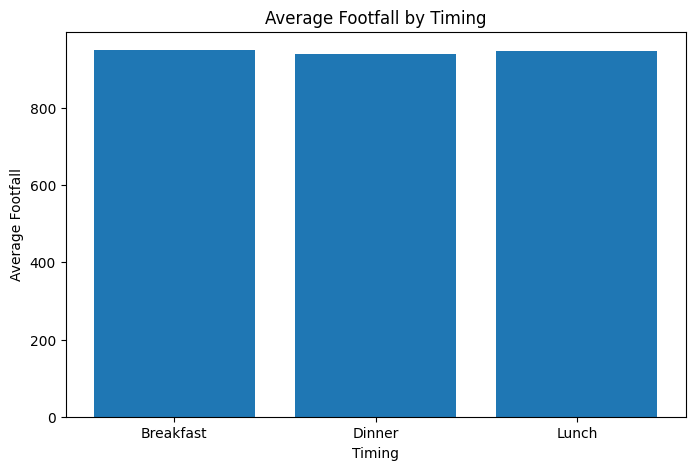

In [31]:
import matplotlib.pyplot as plt

timing_avg = df.groupby('Timing')['NoOfStudents'].mean()

plt.figure(figsize=(8, 5))
plt.bar(timing_avg.index, timing_avg.values)

plt.xlabel('Timing')
plt.ylabel('Average Footfall')
plt.title('Average Footfall by Timing')

plt.show()

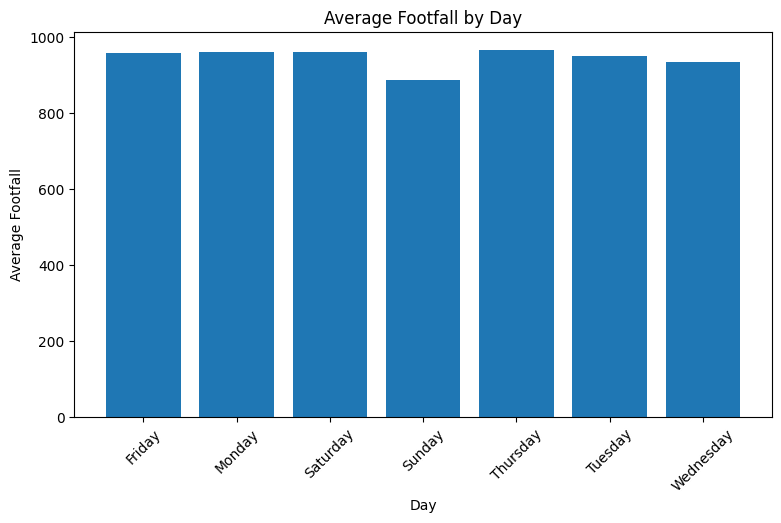

In [32]:
day_avg = df.groupby('Day')['NoOfStudents'].mean()

plt.figure(figsize=(9, 5))
plt.bar(day_avg.index, day_avg.values)

plt.xlabel('Day')
plt.ylabel('Average Footfall')
plt.title('Average Footfall by Day')

plt.xticks(rotation=45)

plt.show()

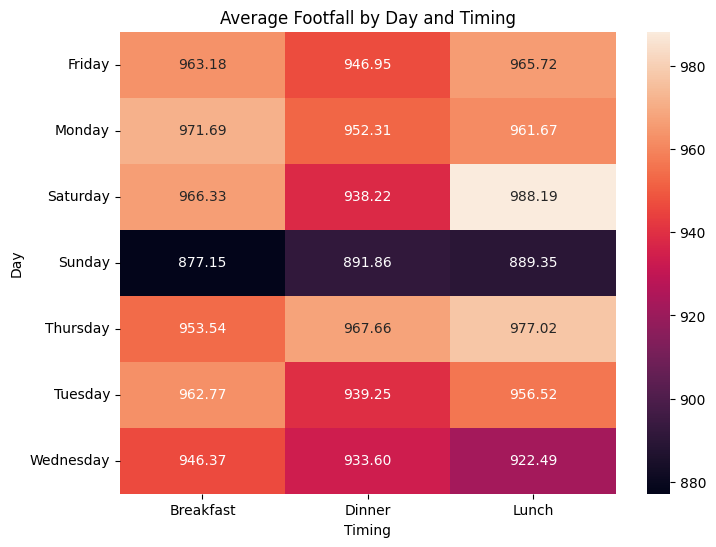

In [33]:
import seaborn as sns
heatmap_data = df.pivot_table(
    values='NoOfStudents',
    index='Day',
    columns='Timing',
    aggfunc='mean'
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f'
)

plt.title('Average Footfall by Day and Timing')
plt.xlabel('Timing')
plt.ylabel('Day')

plt.show()

### **Conclusion**
The retail store footfall dataset was analyzed using NumPy, Pandas, Matplotlib, and Seaborn. The analysis included statistical calculations, grouping based on timing, holiday status and day, data validation, and visualization. The results showed differences in footfall across different days and timings. Thursday had the highest average day-wise footfall, while Sunday had the lowest. Breakfast had the highest average footfall among the three timings. The heatmap also helped identify variations in footfall for different combinations of days and timings. Overall, the analysis provides useful insights into customer footfall patterns in the retail store.